In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF

In [2]:
#X,Y must be a box
Y=[(0,1)]
n=5
X=[]
def fcp(x):
    return x[-1]

def fs(x):
    return np.sin(6*x)+np.log(x+1)
    
def gcp(x,y):
    return (cp.sum([x[i]*y**i for i in range(n)])-fs(y))**2-x[-1]

def f(x):
    return x[-1]

def df(x):
    v=np.zeros(n+1)
    v[-1]=1
    return v


def g(x,y):
    return (np.sum([x[i]*y**i for i in range(n)])-fs(y))**2-x[-1]

def dg(x,y):
    v=np.zeros(n+1)
    v[-1]=-1
    #print([2*y[0]**i*(np.sum([x[i]*y[0]**i for i in range(n)])-fs(y)) for i in range(n)])
    for i in range(n):
        v[i]=2*y[0]**i*(np.sum([x[i]*y[0]**i for i in range(n)])-fs(y))
    return v

def poly(d,coeff,x):
    return np.sum([coeff[i]*x**i for i in range(d)])

In [6]:
y0=np.array([[0],[0.5],[1]])
x0=np.zeros(n+1)
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,rho=1,f=f,df=df,dg=dg)

0.9496603349322099
1.2549834388824677
0.020516914732467306
0.0010511378419860717
0.0010444325356999684
0.00020664892305455318
Time 0.3484961986541748
Time upper problem 0.19596099853515625
Time lower problem 0.15253520011901855
Feasibility 0.00020715021820705282
Final rho 4
Rho increases 2
Optimal value 0.5312793624814947
Value function call 6


In [4]:
res1=AlgBF(x0,y0,fcp,gcp,g,X,Y)

Time 0.3418712615966797
Time upper problem 0.15014934539794922
Time lower problem 0.19172191619873047
Feasibility 6.466671453777238e-05
Optimal value 0.0073042626618751195
Value function call 7


In [5]:
res2=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1)

Time 0.4068179130554199
Time upper problem 0.19866228103637695
Time lower problem 0.20815563201904297
Feasibility -0.0009236361528572748
Optimal value 0.007304751265375866
Optimality cuts 1
Feasibility cuts 7
Value function calls 8


In [8]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y)

Time 7.313357830047607
Time upper problem 3.4988656044006348
Time lower problem 3.8144922256469727
Feasibility 0.000326997486762684
Optimal value 1.9982568375487118e-11
Value function call 14


In [9]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

Time 7.408121824264526
Time upper problem 3.5730819702148438
Time lower problem 3.811164617538452
Feasibility 0.000326997486762684
Optimal value 1.9982568375487118e-11
Value function call 14


In [10]:
res4=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

KeyboardInterrupt: 

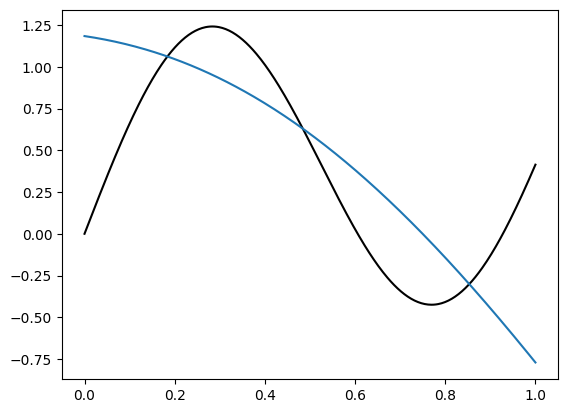

In [7]:
N = 400
x = np.linspace(Y[0][0], Y[0][1], N)


fig, ax = plt.subplots()
ax.plot(x, fs(x), "k")
poly1=[poly(n,res1[0],xi) for xi in x]
ax.plot(x, poly1)

#ax.set(aspect=1)